# Continuo de H₂O y términos T, U, D

H₂O de HITRAN2024 (HAPI, todos los isotopólogos) y la US Standard, en 714–1250 cm⁻¹ (8–14 µm).

- `h2o_continuum=True` suma el continuo MT_CKD 4.3 menos el pedestal de las líneas de H₂O, que MT_CKD ya contiene.
- `compute_tud` da la transmitancia T, la radiancia ascendente U en el tope y la descendente D en la superficie:
  L = ε·B(T_skin)·T + U + (1 − ε)·T·D.

Paso de 0,01 cm⁻¹ para que corra rápido; las figuras van en canales IASI (gaussiana de FWHM 0,5 cm⁻¹).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import fftconvolve

from pylblrtm import compute_transmittance, compute_tud, from_hapi, planck, us_standard_atmosphere
from pylblrtm.continuum import h2o_continuum_optical_depth

NU_MIN, NU_MAX, PASO = 714.0, 1250.0, 0.01
KW = dict(step_cm1=PASO, voigt="humlicek", n_jobs=-1)

sd = from_hapi("H2O", NU_MIN - 25, NU_MAX + 25, iso_id="all")
perfil = us_standard_atmosphere(gases=["H2O"])
print(sd.n_lines, "líneas ·", perfil.n_layers, "capas")

HAPI version: 1.3.0.0
To get the most up-to-date version please check http://hitran.org/hapi
ATTENTION: Python versions of partition sums from TIPS-2021 are now available in HAPI code

           MIT license: Copyright 2021 HITRAN team, see more at http://hitran.org. 

           If you use HAPI in your research or software development,
           please cite it using the following reference:
           R.V. Kochanov, I.E. Gordon, L.S. Rothman, P. Wcislo, C. Hill, J.S. Wilzewski,
           HITRAN Application Programming Interface (HAPI): A comprehensive approach
           to working with spectroscopic data, J. Quant. Spectrosc. Radiat. Transfer 177, 15-30 (2016)
           DOI: 10.1016/j.jqsrt.2016.03.005

           ATTENTION: This is the core version of the HITRAN Application Programming Interface.
                      For more efficient implementation of the absorption coefficient routine, 
                      as well as for new profiles, parameters and other functional,
      


Data is fetched from http://hitran.org



BEGIN DOWNLOAD: H2O_iso1_689_1275
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso1_689_1275.data
Header written to /root/.pylblrtm/hitran_cache/H2O_iso1_689_1275.header
END DOWNLOAD
                     Lines parsed: 2902
PROCESSED
Using /root/.pylblrtm/hitran_cache

H2O_iso1_689_1275


                     Lines parsed: 2902

Data is fetched from http://hitran.org



BEGIN DOWNLOAD: H2O_iso2_689_1275
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso2_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso2_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso2_689_1275.data
Header written to /root/.pylblrtm/hitran_cache/H2O_iso2_689_1275.header
END DOWNLOAD
                     Lines parsed: 847
PROCESSED
Using /root/.pylblrtm/hitran_cache

H2O_iso2_689_1275
                     Lines parsed: 847
H2O_iso1_689_1275
                     Lines parsed: 2902

Data is fetched from http://hitran.org



...

                     Lines parsed: 2902

Data is fetched from http://hitran.org



BEGIN DOWNLOAD: H2O_iso5_689_1275
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso5_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso5_689_1275.data
Header written to /root/.pylblrtm/hitran_cache/H2O_iso5_689_1275.header
END DOWNLOAD
                     Lines parsed: 419
PROCESSED
Using /root/.pylblrtm/hitran_cache

H2O_iso3_689_1275
                     Lines parsed: 537
H2O_iso4_689_1275
                     Lines parsed: 2262
H2O_iso2_689_1275
                     Lines parsed: 847
H2O_iso1_689_1275
                     Lines parsed: 2902
H2O_iso5_689_1275
                     Lines parsed: 419

Data is fetched from http://hitran.org



BEGIN DOWNLOAD: H2O_iso6_689_1275
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso6_689_1275.data
Header written to /root/.pylblrtm/hitran_cache/H2O_iso6_689_1275.header
END DOWNLOAD
                     Lines parsed: 211
PROCESSED
Using /root/.pylblrtm/hitran_cache

H2O_iso6_689_1275
                     Lines parsed: 211
H2O_iso3_689_1275
                     Lines parsed: 537
H2O_iso4_689_1275
                     Lines parsed: 2262
H2O_iso2_689_1275
                     Lines parsed: 847
H2O_iso1_689_1275
                     Lines parsed: 2902
H2O_iso5_689_1275
                     Lines parsed: 419

Data is fetched from http://hitran.org



BEGIN DOWNLOAD: H2O_iso7_689_1275
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso7_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso7_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso7_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso7_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso7_689_1275.data
  65536 bytes written to /root/.pylblrtm/hitran_cache/H2O_iso7_689_1275.data
Header written to /root/.pylblrtm/hitran_cache/H2O_iso7_689_1275.header
END DOWNLOAD
                     Lines parsed: 2349
PROCESSED


9527 líneas · 20 capas


In [2]:
plt.rcParams.update({"font.family": "serif", "axes.linewidth": 1.5, "xtick.major.width": 1.2,
                     "ytick.major.width": 1.2, "figure.dpi": 110})


def iasi(y):
    """Canales IASI: gaussiana de FWHM 0,5 cm⁻¹, cada 0,25 cm⁻¹."""
    s = 0.5 / (2 * np.sqrt(2 * np.log(2))) / PASO
    k = np.exp(-0.5 * (np.arange(-int(6 * s), int(6 * s) + 1) / s) ** 2)
    k /= k.sum()
    return (fftconvolve(y, k, "same") / fftconvolve(np.ones_like(y), k, "same"))[::int(round(0.25 / PASO))]


def tb(nu, L):
    """Temperatura de brillo [K] de una radiancia en W/(cm² sr cm⁻¹)."""
    return 1.4387752 * nu / np.log1p(1.191042972e-12 * nu ** 3 / L)


def dbdt(nu, T):
    """dB/dT [W/(cm² sr cm⁻¹ K)], para pasar diferencias de radiancia a kelvin."""
    x = 1.4387752 * nu / T
    return planck(nu, T) * x / T / -np.expm1(-x)


def ejes(titulo, ylabel):
    """Longitud de onda abajo, número de onda arriba."""
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.set_xlabel("longitud de onda [µm]")
    ax.set_ylabel(ylabel)
    ax.set_title(titulo)
    arriba = ax.secondary_xaxis("top", functions=(lambda x: 1e4 / x, lambda x: 1e4 / x))
    arriba.set_xlabel("número de onda [cm⁻¹]")
    return fig, ax

## 1. Transmitancia con y sin continuo

/tmp/ipykernel_14473/1699882724.py:30: RuntimeWarning: divide by zero encountered in divide
  arriba = ax.secondary_xaxis("top", functions=(lambda x: 1e4 / x, lambda x: 1e4 / x))


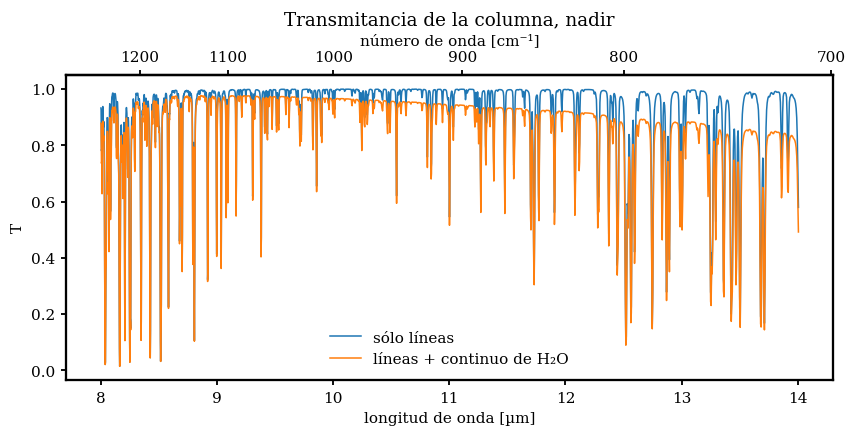

In [3]:
nu, T_lineas = compute_transmittance(sd, perfil, NU_MIN, NU_MAX, **KW)
_, T_continuo = compute_transmittance(sd, perfil, NU_MIN, NU_MAX, h2o_continuum=True, **KW)
nu_c = nu[::int(round(0.25 / PASO))]

fig, ax = ejes("Transmitancia de la columna, nadir", "T")
ax.plot(1e4 / nu_c, iasi(T_lineas), lw=1, label="sólo líneas")
ax.plot(1e4 / nu_c, iasi(T_continuo), lw=1, label="líneas + continuo de H₂O")
ax.legend(frameon=False)
plt.show()

## 2. El continuo y el pedestal que se le resta

/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: Pyp

/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_math

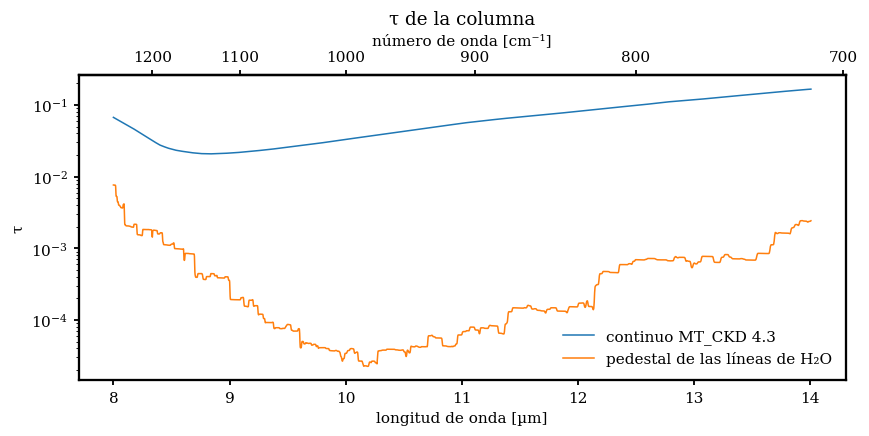

800–1000 cm⁻¹: el pedestal es el 0.21 % del continuo


In [4]:
capas = perfil.build_layers()
mtckd = h2o_continuum_optical_depth(nu, capas).sum(axis=0)
neto = h2o_continuum_optical_depth(nu, capas, sd).sum(axis=0)

fig, ax = ejes("τ de la columna", "τ")
ax.plot(1e4 / nu_c, iasi(mtckd), lw=1, label="continuo MT_CKD 4.3")
ax.plot(1e4 / nu_c, iasi(mtckd - neto), lw=1, label="pedestal de las líneas de H₂O")
ax.set_yscale("log")
ax.legend(frameon=False)
plt.show()
ventana = (nu >= 800) & (nu <= 1000)
print(f"800–1000 cm⁻¹: el pedestal es el {100 * (mtckd - neto)[ventana].mean() / mtckd[ventana].mean():.2f} % del continuo")

## 3. T, U y D

/tmp/ipykernel_14473/1699882724.py:30: RuntimeWarning: divide by zero encountered in divide
  arriba = ax.secondary_xaxis("top", functions=(lambda x: 1e4 / x, lambda x: 1e4 / x))


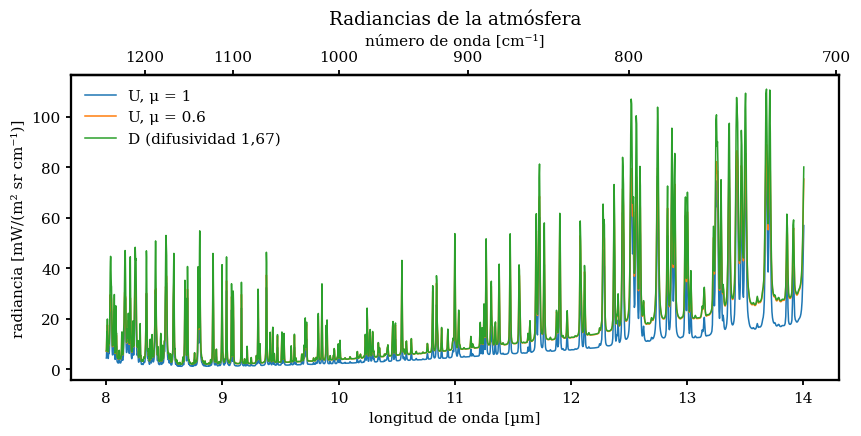

In [5]:
tud = {mu: compute_tud(sd, perfil, NU_MIN, NU_MAX, mu_view=mu, h2o_continuum=True, **KW)
       for mu in (1.0, 0.6)}
_, T1, U1, D1 = tud[1.0]

fig, ax = ejes("Radiancias de la atmósfera", "radiancia [mW/(m² sr cm⁻¹)]")
for mu, (_, T, U, D) in tud.items():
    ax.plot(1e4 / nu_c, iasi(U) * 1e7, lw=1, label=f"U, μ = {mu:g}")
ax.plot(1e4 / nu_c, iasi(D1) * 1e7, lw=1, label="D (difusividad 1,67)")
ax.legend(frameon=False)
plt.show()

/tmp/ipykernel_14473/1699882724.py:30: RuntimeWarning: divide by zero encountered in divide
  arriba = ax.secondary_xaxis("top", functions=(lambda x: 1e4 / x, lambda x: 1e4 / x))


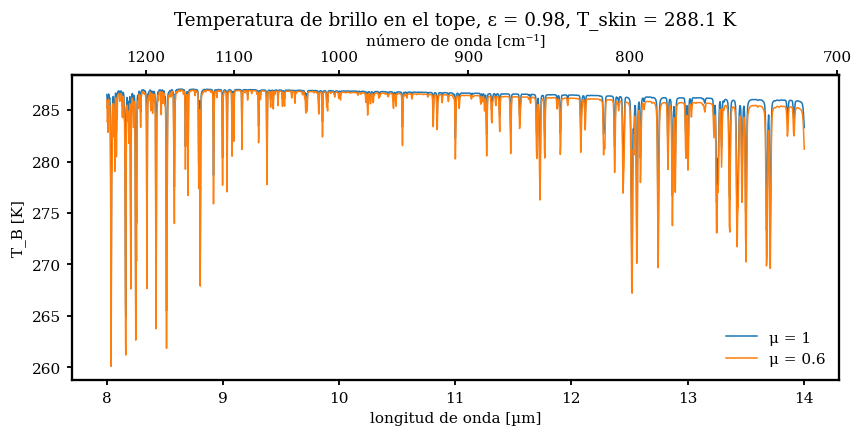

In [6]:
eps, T_skin = 0.98, float(perfil.temperature_k[-1])

fig, ax = ejes(f"Temperatura de brillo en el tope, ε = {eps}, T_skin = {T_skin:.1f} K", "T_B [K]")
for mu, (_, T, U, D) in tud.items():
    L = eps * planck(nu, T_skin) * T + U + (1 - eps) * T * D
    ax.plot(1e4 / nu_c, tb(nu_c, iasi(L)), lw=1, label=f"μ = {mu:g}")
ax.legend(frameon=False)
plt.show()

## 4. La B de cada capa

`layer_planck`: `"layer"` (B de la temperatura de la capa, la de las líneas; por defecto), `"density"`
(B de la temperatura ponderada por masa) o `"arithmetic"` (media de B en los dos niveles). Diferencia con
`"layer"`, en kelvin equivalentes a la T de superficie.

/tmp/ipykernel_14473/1699882724.py:30: RuntimeWarning: divide by zero encountered in divide
  arriba = ax.secondary_xaxis("top", functions=(lambda x: 1e4 / x, lambda x: 1e4 / x))


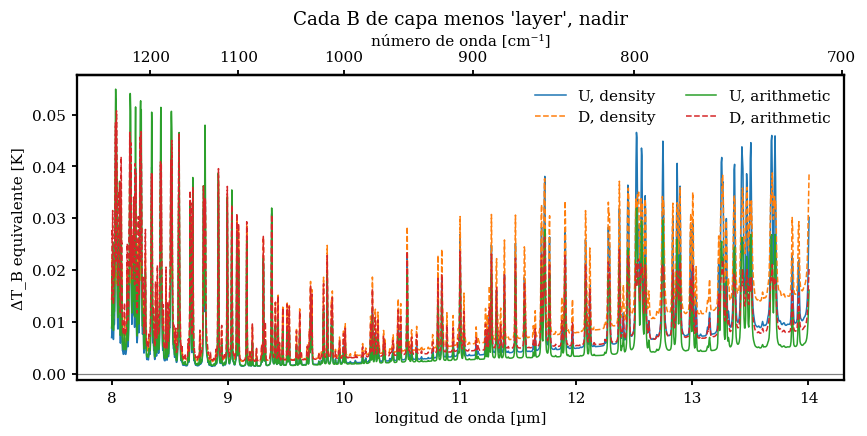

In [7]:
fig, ax = ejes("Cada B de capa menos 'layer', nadir", "ΔT_B equivalente [K]")
for opcion in ("density", "arithmetic"):
    _, _, U, D = compute_tud(sd, perfil, NU_MIN, NU_MAX, layer_planck=opcion, h2o_continuum=True, **KW)
    ax.plot(1e4 / nu_c, (iasi(U) - iasi(U1)) / dbdt(nu_c, T_skin), lw=1, label=f"U, {opcion}")
    ax.plot(1e4 / nu_c, (iasi(D) - iasi(D1)) / dbdt(nu_c, T_skin), lw=1, ls="--", label=f"D, {opcion}")
ax.axhline(0, color="0.5", lw=0.8)
ax.legend(frameon=False, ncol=2)
plt.show()